# The Hardy Weinberg principle

dThis notebook focuses on highlighting the Hardy Weinberg equilibrium principle in a population of diploids with no evolutionary mechanisms.

The simulated population is based on the following conditions:
* No mutations
* No natural or sexual selection
* No migration
* Large population of constant size

We focus on one particular locus which presents two alleles : A and a.
As a diploid, each individual carries two copies of the observed gene.

Thus, the possible genotypes are AA, Aa (or aA) and aa.

In [57]:
import matplotlib.pyplot as plt
import random

In [54]:
class Population:
    def __init__(self, list_of_individuals: list[list[int]]):
        self.list_of_individuals = list_of_individuals

        self.population_size = len(list_of_individuals)

        self.number_of_dominant_homozygous = list_of_individuals.count([1,1])
        self.number_of_recessive_homozygous = list_of_individuals.count([0,0])
        self.number_of_heterozygous = list_of_individuals.count([0,1]) + list_of_individuals.count([1,0])


        self.frequency_of_dominant_homozygous = list_of_individuals.count([1,1])/len(list_of_individuals)
        self.frequency_of_recessive_homozygous = list_of_individuals.count([0,0])/len(list_of_individuals)


    def is_in_hardy_weinberg_equilibrium(self):
        pAA = self.frequency_of_dominant_homozygous
        paa = self.frequency_of_recessive_homozygous
        pAa = 1 - (pAA+paa)
        print(f'''pAA={round(pAA, 2)}
paa={round(paa, 2)}
pAa={round(pAa, 2)}''')

        pA = pAA + 0.5*pAa
        pa = paa + 0.5*pAa
        print(f'''pA={round(pA, 2)}
pa={round(pa, 2)}''')

        if round(pA**2, 2) == round(pAA, 2) or round(pa**2, 2) == round(paa, 2) or round(2*pA*pa, 2) == round(pAa, 2):
            print("The population is in the Hardy Weinberg proportions")
            return True
        else :
            print("The population is not in the Hardy Weinberg proportions")
            return False

    def next_generation_individuals(self):
        new_generation_individuals = []

        for i in range(self.population_size):

            mom = self.list_of_individuals[random.randint(0,self.population_size-1)]
            dad = self.list_of_individuals[random.randint(0,self.population_size-1)]

            child = [mom[random.randint(0,1)], dad[random.randint(0,1)]]
            new_generation_individuals.append(child)


        random.shuffle(new_generation_individuals)

        return new_generation_individuals


In [69]:
N = 10000 # Population size
p_AA = 0.5 # Frequency of genotype AA
p_aa = 0.3 # Frequency of genotype aa

In [70]:
# Population initialization

individual_list = []
number_of_dominant_homozygous = int(round(p_AA*N, 0))
number_of_recessive_homozygous = int(round(p_aa*N, 0))
number_of_heterozygous = N - (number_of_dominant_homozygous + number_of_recessive_homozygous)
for i in range(number_of_dominant_homozygous):
    individual_list.append([1,1])
for i in range(number_of_recessive_homozygous):
    individual_list.append([0,0])
for i in range(number_of_heterozygous):
    individual_list.append([0,1])

random.shuffle(individual_list)
population = Population(individual_list)

p_A = p_AA + 0.5*(1-(p_AA+p_aa))
p_a = p_aa + 0.5*(1-(p_AA+p_aa))

print(f'''---Population initialized with following parameters:---
Population size N: {N}
Dominant homozygous population AA: {p_AA} ({number_of_dominant_homozygous} individuals)
Recessive homozygous population aa: {p_aa} ({number_of_recessive_homozygous} individuals)
Heterozygous population Aa: {round(1-(p_AA+p_aa), 2)} ({number_of_heterozygous} individuals)

Frequency of allele A in the population: {round(p_A, 2)}
Frequency of allele a in the population: {round(p_a, 2)}
            ''')

---Population initialized with following parameters:---
Population size N: 10000
Dominant homozygous population AA: 0.5 (5000 individuals)
Recessive homozygous population aa: 0.3 (3000 individuals)
Heterozygous population Aa: 0.2 (2000 individuals)

Frequency of allele A in the population: 0.6
Frequency of allele a in the population: 0.4
            


In [71]:
population.is_in_hardy_weinberg_equilibrium()

pAA=0.5
paa=0.3
pAa=0.2
pA=0.6
pa=0.4
The population is not in the Hardy Weinberg proportions


False

In [72]:
next_generation_population = Population(population.next_generation_individuals())

p_A = next_generation_population.frequency_of_dominant_homozygous + 0.5*(1-(next_generation_population.frequency_of_dominant_homozygous+next_generation_population.frequency_of_recessive_homozygous))
p_a = next_generation_population.frequency_of_recessive_homozygous + 0.5*(1-(next_generation_population.frequency_of_dominant_homozygous+next_generation_population.frequency_of_recessive_homozygous))

print(f'''---Next generation:---
Population size N: {N}
Dominant homozygous population AA: {next_generation_population.frequency_of_dominant_homozygous} ({next_generation_population.number_of_dominant_homozygous} individuals)
Recessive homozygous population aa: {next_generation_population.frequency_of_recessive_homozygous} ({next_generation_population.number_of_recessive_homozygous} individuals)
Heterozygous population Aa: {round(1-(next_generation_population.frequency_of_dominant_homozygous+next_generation_population.frequency_of_recessive_homozygous), 2)} ({next_generation_population.number_of_heterozygous} individuals)

Frequency of allele A in the population: {round(p_A, 2)}
Frequency of allele a in the population: {round(p_a, 2)}
''')



---Next generation:---
Population size N: 10000
Dominant homozygous population AA: 0.3642 (3642 individuals)
Recessive homozygous population aa: 0.1559 (1559 individuals)
Heterozygous population Aa: 0.48 (4799 individuals)

Frequency of allele A in the population: 0.6
Frequency of allele a in the population: 0.4



In [73]:
next_generation_population.is_in_hardy_weinberg_equilibrium()

pAA=0.36
paa=0.16
pAa=0.48
pA=0.6
pa=0.4
The population is in the Hardy Weinberg proportions


True

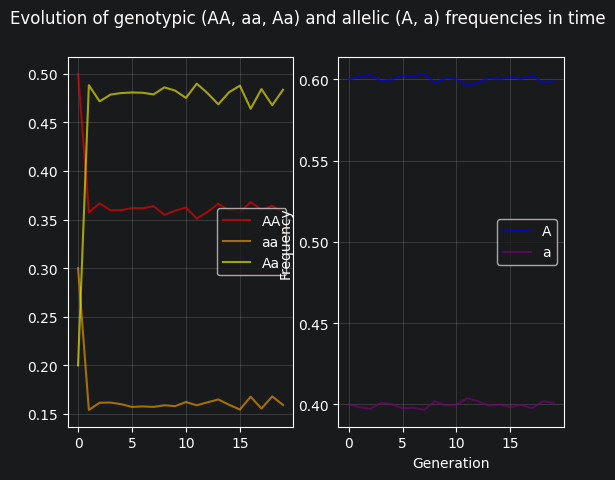

In [81]:
T = 20 #Number of generations

generations = []
dominant_homozygous_in_time = []
recessive_homozygous_in_time = []
heterozygous_in_time = []

dominant_allele_in_time = []
recessive_allele_in_time = []

simulated_population = population

for generation in range(T):
    generations.append(generation)

    p_AA = simulated_population.number_of_dominant_homozygous/simulated_population.population_size
    p_aa = simulated_population.number_of_recessive_homozygous/simulated_population.population_size
    p_Aa = simulated_population.number_of_heterozygous/simulated_population.population_size

    dominant_homozygous_in_time.append(p_AA)
    recessive_homozygous_in_time.append(p_aa)
    heterozygous_in_time.append(p_Aa)

    dominant_allele_in_time.append(p_AA+0.5*p_Aa)
    recessive_allele_in_time.append(p_aa+0.5*p_Aa)

    simulated_population = Population(population.next_generation_individuals())

fig, (ax1, ax2) = plt.subplots(1, 2)

fig.suptitle('Evolution of genotypic (AA, aa, Aa) and allelic (A, a) frequencies in time')

ax1.plot(generations, dominant_homozygous_in_time, alpha=0.6, color='red', label='AA')
ax1.plot(generations, recessive_homozygous_in_time, alpha=0.6, color='orange', label='aa')
ax1.plot(generations, heterozygous_in_time, alpha=0.6, color='yellow', label='Aa')

ax1.legend(['AA', 'aa', 'Aa'])

ax2.plot(generations, dominant_allele_in_time, alpha=0.6, color='blue', label='A')
ax2.plot(generations, recessive_allele_in_time, alpha=0.6, color='purple' , label='a')

ax2.legend(['A', 'a'])

ax1.grid(alpha=0.3)
ax2.grid(alpha=0.3)

plt.xlabel('Generation')
plt.ylabel('Frequency')

plt.show()